# Modelado de Clustering: Perfiles de Consumo Musical de Usuarios (Last.fm, 2005–2014)

## Objetivo del modelado
Construir y evaluar agrupamientos (**clustering**) de **perfiles de usuario** a partir de su historial de reproducciones y los descriptores acústicos de las canciones escuchadas, con el fin de identificar patrones o "modos de escucha" diferenciados dentro de la plataforma y caracterizar qué distingue a cada grupo.

## Datos y tablas limpias consumidas
El análisis parte del corpus **Culture-Aware Music Recommendation Dataset** (Zangerle, Pichl y Schedl, 2020) y del catálogo de artistas del **LFM-1b** (artistas y descriptores de audio de Spotify), utilizando las tablas depuradas en la etapa de limpieza (`data/clean/`) y el catálogo de artistas:
* **`events_clean` (`events_clean.parquet`)**: eventos de reproducción válidos (~350,74 millones de escuchas tras descartar registros anteriores a 2005 y días anómalos con más de 720 escuchas por usuario y día).
* **`acoustic_clean` (`acoustic_clean.parquet`)**: descriptores acústicos de las canciones (~3,47 millones de pistas), donde valores fuera de rango o faltantes ocultos (`tempo = 0`, `loudness = -60`) fueron convertidos a `NULL`.
* **`users_clean` (`users_clean.parquet`)**: metadatos de los 55.190 usuarios, con edades fuera de `[10, 90]` (incluido `-1`) llevadas a `NULL`, género normalizado a `'m'`, `'f'` o `'no informado'`, y códigos de país unificados (`UK` $\rightarrow$ `GB`).
* **`artists`**: catálogo de artistas (`artist_id`, `artist_name`, `gender_counts`) para interpretar y contextualizar los consumos asociados a los perfiles.

## Preguntas que busca responder este notebook
1. ¿Existen perfiles o segmentos diferenciados de usuarios según sus hábitos de reproducción y el perfil acústico promedio/dispersión de las pistas que escuchan?
2. ¿Cómo se comportan y comparan distintas familias y configuraciones de clustering (partición, jerárquico y densidad) sobre estos perfiles, y qué aporta la acumulación de evidencia para evaluar estabilidad?
3. ¿Qué variables originales describen y separan mejor a cada cluster (mediante análisis exploratorio por grupo y un árbol de decisión descriptivo)?
4. ¿Cómo se distribuyen los clusters hallados al contrastarlos con atributos de contexto como demografía/país (`users_clean`) o artistas representativos (`artists`)?

## 1. Carga, preparación y escalado de datos

En este bloque se carga la vista minable `vista_usuarios` (construida a partir de `events_clean`, `acoustic_clean` y `users_clean`) y se contrasta con los metadatos demográficos de `users_clean` para mantener la trazabilidad contextual.

Antes de calcular distancias geométricas entre perfiles de usuario, es necesario:
- **Inspeccionar nulos y distribuciones:** las métricas de volumen o diversidad de escucha suelen presentar fuerte asimetría positiva (cola larga), mientras que las variables acústicas o proporciones tienen rangos distintos.
- **Aplicar transformaciones y escalado:** se transforman las variables de conteo fuertemente sesgadas (por ejemplo, con `log1p`) y se estandarizan todas las variables seleccionadas con `StandardScaler` para evitar que las variables de mayor escala dominen la distancia euclídea.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

from config import conectar, ruta_sql

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

con = conectar()
con.execute(f"CREATE OR REPLACE VIEW vista_usuarios AS SELECT * FROM {ruta_sql('vista_usuarios')}")
con.execute(f"CREATE OR REPLACE VIEW users_clean AS SELECT * FROM {ruta_sql('users_clean')}")
con.execute(f"CREATE OR REPLACE VIEW artists AS SELECT * FROM {ruta_sql('artists')}")

df_usuarios = con.sql("""
    SELECT
        v.*,
        u.country,
        u.age,
        u.gender
    FROM vista_usuarios v
    LEFT JOIN users_clean u USING (user_id)
""").df()

print("Dimensiones de vista_usuarios + demografía:", df_usuarios.shape)
display(df_usuarios.head(3))

# Selección de variables numéricas del perfil de usuario (excluyendo identificadores y contexto)
cols_excluir = {"user_id", "country", "age", "gender"}
features_base = [
    c for c in df_usuarios.select_dtypes(include=[np.number]).columns
    if c not in cols_excluir
]

print(f"Variables candidatas ({len(features_base)}):", features_base)
print("\nNulos en variables candidatas:")
print(df_usuarios[features_base].isna().sum()[lambda s: s > 0])

# Copia de trabajo limpia para clustering (imputación por mediana si hubiera algún nulo residual)
df_cluster = df_usuarios.copy()
for col in features_base:
    if df_cluster[col].isna().any():
        df_cluster[col] = df_cluster[col].fillna(df_cluster[col].median())

# Transformación log1p para variables de conteo/volumen fuertemente sesgadas
cols_log = [
    c for c in features_base
    if any(k in c.lower() for k in ["escuchas", "reproducciones", "artistas_distintos", "pistas_distintas", "sesiones", "count", "total"])
    and (df_cluster[c].min() >= 0)
    and (df_cluster[c].skew() > 1.5)
]

X_transformado = df_cluster[features_base].copy()
for col in cols_log:
    X_transformado[col] = np.log1p(X_transformado[col])

print("Variables transformadas con log1p:", cols_log)

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_transformado),
    columns=features_base,
    index=df_cluster.index,
)

# Submuestra reproducible para algoritmos costosos en memoria/tiempo (jerárquico, DBSCAN completo y matriz de evidencia)
N_MUESTRA = min(5000, len(X_scaled))
idx_sample = X_scaled.sample(n=N_MUESTRA, random_state=RANDOM_STATE).index
X_sample_scaled = X_scaled.loc[idx_sample]
df_sample = df_cluster.loc[idx_sample]
print(f"Submuestra de trabajo para experimentación intensiva: {len(X_sample_scaled)} usuarios")

Dimensiones de vista_usuarios + demografía: (53289, 23)


,user_id,total_escuchas,artistas_distintos,escuchas_con_audio,pct_escuchas_con_audio,energy_media,energy_std,valence_media,valence_std,dance_media,...,speechiness_media,loudness_media,popularidad_media,pct_artista_top,country,age,gender,country_1,age_1,gender_1
0,2798275,495,71,495,1.0,0.792042,0.178658,0.561381,0.221126,0.500276,...,0.064073,-5.182364,1.669794,0.197980,CL,27,f,CL,27,f
1,3507776,3450,220,3450,1.0,0.836649,0.166821,0.298755,0.202277,0.565086,...,0.057701,-7.122546,2.435869,0.044348,HR,27,m,HR,27,m
2,2115525,7452,140,7452,1.0,0.876845,0.163111,0.478705,0.251206,0.433163,...,0.090603,-5.666253,3.273343,0.359501,FI,23,no informado,FI,23,no informado


Variables candidatas (17): ['total_escuchas', 'artistas_distintos', 'escuchas_con_audio', 'pct_escuchas_con_audio', 'energy_media', 'energy_std', 'valence_media', 'valence_std', 'dance_media', 'acoustic_media', 'instrumental_media', 'tempo_medio', 'speechiness_media', 'loudness_media', 'popularidad_media', 'pct_artista_top', 'age_1']

Nulos en variables candidatas:
age_1    11961
dtype: int64
Variables transformadas con log1p: ['total_escuchas', 'artistas_distintos', 'escuchas_con_audio']
Submuestra de trabajo para experimentación intensiva: 5000 usuarios


### Hallazgos exploratorios y decisiones de preparación (Bloque 1)

A partir de la inspección inicial de `vista_usuarios` (**53.289 usuarios** activos con al menos 100 escuchas con descriptores de audio) y su cruce con los metadatos demográficos de `users_clean`, se establecen las siguientes decisiones metodológicas para el modelado de clustering:

1. **Integridad de datos y manejo de valores faltantes:**
   - Las variables de comportamiento de escucha (`total_escuchas`, `artistas_distintos`, `popularidad_media`, `pct_artista_top`) y los diez descriptores acústicos agregados (`energy_media`, `energy_std`, `valence_media`, `valence_std`, `dance_media`, `acoustic_media`, `instrumental_media`, `tempo_medio`, `speechiness_media`, `loudness_media`) presentan **0 valores faltantes**.
   - La única variable con datos ausentes es `age` (11.961 registros sin edad informada), por lo que no se incorpora en el cálculo de distancias y se reserva junto con `country` y `gender` para la etapa de contextualización e interpretación posterior.
   - Se excluyen columnas redundantes o constantes (`escuchas_con_audio`, idéntica a `total_escuchas`, y `pct_escuchas_con_audio`, constante igual a `1,0`) para no duplicar información ni introducir varianza nula.

2. **Asimetría (sesgo de cola larga) y transformación logarítmica:**
   - Las métricas de volumen y amplitud de consumo (`total_escuchas`, con media $\approx 6.580$, y `artistas_distintos`, con media $\approx 337,37$) exhiben una marcada **asimetría positiva**: la mayoría de los usuarios concentra valores moderados, mientras que un subconjunto reducido de oyentes intensivos alcanza decenas o cientos de miles de reproducciones.
   - En algoritmos basados en distancias geométricas (como la distancia euclídea), esa cola larga hace que las diferencias en los extremos dominen por completo la separación entre usuarios. Para comprimir el rango dinámico y volver comparables las diferencias relativas, se aplica una transformación **`log1p`** sobre dichas variables antes de escalar.

3. **Relación entre variables (correlación y redundancia estructural):**
   - **Actividad vs. diversidad de artistas:** al contrastar `total_escuchas` con `artistas_distintos` se observa una asociación creciente pero dispersa, donde la correlación de **Spearman** ($\rho \approx 0,61$) supera a la de **Pearson** ($r \approx 0,47$). Esto indica una relación **monótona pero no lineal** en escala original: a mayor volumen de escucha tiende a ampliarse el repertorio, aunque coexisten oyentes exploradores con usuarios intensivos muy concentrados en pocos artistas (capturado también por `pct_artista_top`).
   - **Colinealidad entre rasgos acústicos:** la matriz de correlación evidencia asociaciones lineales fuertes entre pares de descriptores sonoros, destacándose `energy_media` con `acoustic_media` ($r \approx -0,95$), `energy_media` con `loudness_media` ($r \approx 0,88$), `acoustic_media` con `loudness_media` ($r \approx -0,83$) y `valence_media` con `dance_media` ($r \approx 0,75$). Tener presentes estas dependencias resulta clave al interpretar los clusters, ya que estos ejes acústicos tienden a variar de forma conjunta y a traccionar la formación de perfiles sonoros definidos.

4. **Estandarización y submuestra de experimentación:**
   - Finalmente, se aplica **`StandardScaler`** (media 0 y desvío estándar 1) sobre el conjunto de variables transformadas para equilibrar la contribución de cada dimensión en el cálculo de distancias, y se fija una submuestra reproducible de **5.000 usuarios** (`random_state=42`) para evaluar de forma comparativa las familias jerárquica y basada en densidad junto con la matriz de evidencia.

## 2. Experimentación con técnicas y configuraciones de clustering

Para evaluar cómo emerge la estructura de perfiles musicales bajo distintos supuestos geométricos y de densidad, se prueban configuraciones en las tres familias estudiadas en el curso:
- **Partición (`KMeans`):** agrupa minimizando la varianza intra-cluster alrededor de centroides; requiere fijar $k$ de antemano y resulta adecuado para grupos compactos en el espacio escalado.
- **Jerárquico (`AgglomerativeClustering`):** construye una jerarquía de fusiones o divisiones según criterios de enlace (`ward`, `complete`, `average`), permitiendo inspeccionar la estructura multinivel mediante un dendrograma.
- **Densidad (`DBSCAN`):** identifica regiones densas (`core` y `border`) y separa puntos aislados como ruido (`-1`) sin imponer forma esférica ni cantidad fija de clusters.

Cada configuración se evalúa con **Silhouette** (mayor es mejor, mide cohesión vs. separación), **Davies-Bouldin** (menor es mejor, relación dispersión interna vs. distancia entre centroides) y **Calinski-Harabasz** (mayor es mejor, razón de dispersión inter-cluster vs. intra-cluster).

,familia,configuracion,n_clusters,pct_ruido,silhouette,davies_bouldin,calinski_harabasz
8,Jerárquico,"linkage=average, k=4",4,0.00,0.579817,0.444572,30.056898
9,Densidad (DBSCAN),"eps=1.8, min_samples=10",2,15.76,0.390577,0.694517,38.564567
7,Jerárquico,"linkage=complete, k=4",4,0.00,0.337984,1.177222,90.743302
0,Partición (KMeans),k=3,3,0.00,0.167750,1.795797,1154.897875
2,Partición (KMeans),k=5,5,0.00,0.159085,1.682965,910.574688
3,Partición (KMeans),k=6,6,0.00,0.155635,1.674658,833.641716
1,Partición (KMeans),k=4,4,0.00,0.151636,1.846046,965.297073
4,Partición (KMeans),k=8,8,0.00,0.134171,1.676554,735.148739
5,Jerárquico,"linkage=ward, k=4",4,0.00,0.088594,2.049947,760.688203
6,Jerárquico,"linkage=ward, k=5",5,0.00,0.073461,2.180781,681.656812


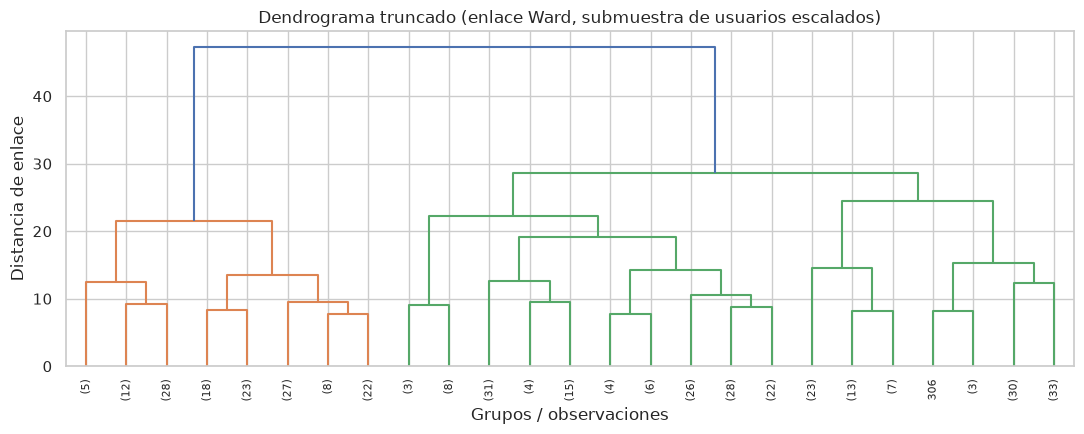

In [4]:
# Aseguramos la matriz de variables de clustering sin columnas duplicadas ni constantes
cols_duplicadas = [c for c in df_usuarios.columns if c.endswith("_1")]
df_cluster = df_usuarios.drop(columns=cols_duplicadas).copy()

features_clustering = [
    c for c in [
        "artistas_distintos",
        "popularidad_media",
        "pct_artista_top",
        "energy_media",
        "energy_std",
        "valence_media",
        "valence_std",
        "dance_media",
        "acoustic_media",
        "instrumental_media",
        "tempo_medio",
        "speechiness_media",
        "loudness_media",
    ]
    if c in df_cluster.columns
]

for col in features_clustering:
    if df_cluster[col].isna().any():
        df_cluster[col] = df_cluster[col].fillna(df_cluster[col].median())

cols_log = [
    c for c in ["artistas_distintos"]
    if c in features_clustering and df_cluster[c].min() >= 0
]

X_transformado = df_cluster[features_clustering].copy()
for col in cols_log:
    X_transformado[col] = np.log1p(X_transformado[col])

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_transformado),
    columns=features_clustering,
    index=df_cluster.index,
)

# Reutilizamos idx_sample si ya existe; si no, lo creamos de forma reproducible
if "idx_sample" not in globals():
    idx_sample = X_scaled.sample(n=min(5000, len(X_scaled)), random_state=RANDOM_STATE).index

X_sample_scaled = X_scaled.loc[idx_sample]

resultados_metricas = []
modelos_sample = {}

# 1) Partición: KMeans con distintas cantidades de clusters
for k in [3, 4, 5, 6, 8]:
    km_full = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels_full = km_full.fit_predict(X_scaled)
    df_cluster[f"kmeans_k{k}"] = labels_full

    labels_sub = pd.Series(labels_full, index=X_scaled.index).loc[idx_sample].to_numpy()
    modelos_sample[f"kmeans_k{k}"] = labels_sub

    resultados_metricas.append({
        "familia": "Partición (KMeans)",
        "configuracion": f"k={k}",
        "n_clusters": k,
        "pct_ruido": 0.0,
        "silhouette": silhouette_score(X_sample_scaled, labels_sub),
        "davies_bouldin": davies_bouldin_score(X_sample_scaled, labels_sub),
        "calinski_harabasz": calinski_harabasz_score(X_sample_scaled, labels_sub),
    })

# 2) Jerárquico: AgglomerativeClustering con distintos enlaces y cortes
for enlace, n_c in [("ward", 4), ("ward", 5), ("complete", 4), ("average", 4)]:
    agg = AgglomerativeClustering(n_clusters=n_c, linkage=enlace, metric="euclidean")
    labels_sub = agg.fit_predict(X_sample_scaled)
    nombre_cfg = f"agg_{enlace}_k{n_c}"
    modelos_sample[nombre_cfg] = labels_sub

    resultados_metricas.append({
        "familia": "Jerárquico",
        "configuracion": f"linkage={enlace}, k={n_c}",
        "n_clusters": n_c,
        "pct_ruido": 0.0,
        "silhouette": silhouette_score(X_sample_scaled, labels_sub),
        "davies_bouldin": davies_bouldin_score(X_sample_scaled, labels_sub),
        "calinski_harabasz": calinski_harabasz_score(X_sample_scaled, labels_sub),
    })

# 3) Densidad: DBSCAN con distintas combinaciones de eps y min_samples
for eps, min_s in [(1.8, 10), (2.2, 10), (2.5, 15), (3.0, 15)]:
    db = DBSCAN(eps=eps, min_samples=min_s, metric="euclidean")
    labels_sub = db.fit_predict(X_sample_scaled)
    nombre_cfg = f"dbscan_eps{eps}_ms{min_s}"
    modelos_sample[nombre_cfg] = labels_sub

    mask_validos = labels_sub != -1
    n_clusters_db = len(set(labels_sub[mask_validos]))
    pct_ruido = float((labels_sub == -1).mean() * 100)

    if n_clusters_db >= 2 and mask_validos.sum() > n_clusters_db:
        sil = silhouette_score(X_sample_scaled.loc[mask_validos], labels_sub[mask_validos])
        db_idx = davies_bouldin_score(X_sample_scaled.loc[mask_validos], labels_sub[mask_validos])
        ch_idx = calinski_harabasz_score(X_sample_scaled.loc[mask_validos], labels_sub[mask_validos])
    else:
        sil, db_idx, ch_idx = np.nan, np.nan, np.nan

    resultados_metricas.append({
        "familia": "Densidad (DBSCAN)",
        "configuracion": f"eps={eps}, min_samples={min_s}",
        "n_clusters": n_clusters_db,
        "pct_ruido": round(pct_ruido, 2),
        "silhouette": sil,
        "davies_bouldin": db_idx,
        "calinski_harabasz": ch_idx,
    })

df_metricas = pd.DataFrame(resultados_metricas)
display(df_metricas.sort_values(by="silhouette", ascending=False))

# Dendrograma ilustrativo con enlace Ward sobre una submuestra de 400 usuarios
idx_dendro = X_sample_scaled.sample(n=min(400, len(X_sample_scaled)), random_state=RANDOM_STATE).index
Z_ward = linkage(X_sample_scaled.loc[idx_dendro], method="ward")

plt.figure(figsize=(11, 4.5))
dendrogram(Z_ward, truncate_mode="lastp", p=25, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrograma truncado (enlace Ward, submuestra de usuarios escalados)")
plt.xlabel("Grupos / observaciones")
plt.ylabel("Distancia de enlace")
plt.tight_layout()
plt.show()

### Hallazgos y lectura comparativa del Bloque 2

Al contrastar las tres familias de clustering sobre la submuestra de **5.000 usuarios** estandarizados (y el dendrograma de enlace *Ward*), se observan diferencias claras según el criterio geométrico de cada método:

1. **Partición (`KMeans`):**
   - No deja observaciones sin asignar (`0,00%` de ruido) y logra los valores más altos de **Calinski-Harabasz** (destacándose `k=3` con `1.154,90`, seguido de `k=4` con `965,30` y `k=5` con `910,57`), reflejando una partición global más repartida entre grupos.
   - Sus valores de **Silhouette** (`0,134` a `0,168`) y **Davies-Bouldin** (`1,67` a `1,85`) son moderados, lo cual es habitual en perfiles de consumo musical donde los hábitos y descriptores acústicos forman gradientes continuos más que esferas totalmente disjuntas.

2. **Jerárquico (`AgglomerativeClustering` y dendrograma `ward`):**
   - El enlace **`average` (`k=4`)** obtiene el mejor **Silhouette** (`0,580`) y el menor **Davies-Bouldin** (`0,445`), pero un **Calinski-Harabasz** bajo (`30,06`), señal de que aisla grupos pequeños/específicos frente a una masa principal, lo que eleva el puntaje por muestra sin maximizar la dispersión global ponderada entre grupos.
   - El enlace **`complete` (`k=4`)** queda en un punto intermedio (`Silhouette = 0,338`, `Davies-Bouldin = 1,177`, `Calinski-Harabasz = 90,74`).
   - El enlace **`ward` (`k=4` y `k=5`)** conserva un **Calinski-Harabasz** relativamente alto (`760,69` y `681,66`) al minimizar varianza intra-cluster, pero con **Silhouette** bajo (`0,089` y `0,073`). En el dendrograma truncado se aprecia un salto marcado de distancia cerca de `~47` que separa dos macro-ramas y subramas internas de distinto tamaño (incluido un bloque concentrado de `306` usuarios en el lado derecho).

3. **Densidad (`DBSCAN`):**
   - Con `eps=1.8` y `min_samples=10` identifica **2 clusters** densos y un **`15,76%` de ruido** (`-1`), alcanzando un **Silhouette** de `0,391` y **Davies-Bouldin** de `0,695` sobre los puntos asignados a clusters.
   - Al ampliar el radio (`eps=2.2`, `2.5` y `3.0`), el vecindario absorbe casi todos los puntos en **1 único cluster** (`n_clusters = 1`, índices no definidos) y reduce el ruido al `6,68%`, `4,30%` y `1,90%`, confirmando que la densidad varía de forma gradual y no en núcleos aislados rígidos.

**Implicancia para el Bloque 3:** como cada familia privilegia un aspecto distinto (cohesión local/aislamiento de atípicos vs. partición global balanceada), conviene aplicar **acumulación de evidencia** combinando las 12 configuraciones para evaluar qué agrupamientos mantienen consistencia entre métodos.

## 3. Acumulación de evidencia y consenso entre configuraciones

Para no depender de un único algoritmo ni de un solo criterio de validación, se aplica **acumulación de evidencia** sobre las **12 configuraciones** evaluadas en el bloque anterior (4 de partición con `KMeans`, 4 jerárquicas con `AgglomerativeClustering` y 4 de densidad con `DBSCAN`).

La lógica consiste en:
- Construir una **matriz de co-ocurrencia** donde cada par de usuarios suma evidencia cada vez que comparten cluster en una configuración (excluyendo el ruido `-1` de `DBSCAN`), normalizada a similitud en $[0, 1]$ y convertida en distancia $d = 1 - s$.
- Aplicar un enlace jerárquico (`average`) sobre esa matriz de consenso y graficar el dendrograma de evidencia para inspeccionar los cortes candidatos ($k \in \{3, 4, 5\}$) y medir su concordancia (mediante **Adjusted Rand Index**, **Silhouette** y **Davies-Bouldin**) frente a las particiones individuales.

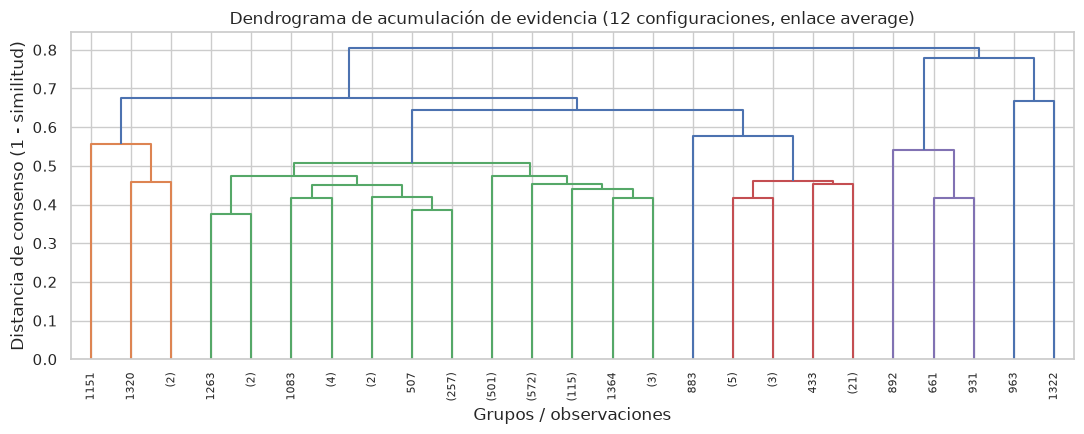

,k_consenso,silhouette_ev,davies_bouldin_ev,calinski_harabasz_ev,ari_vs_kmeans_k3,ari_vs_kmeans_k4
0,3,0.367410,0.932139,13.354958,0.000231,0.001484
1,4,0.301532,1.279889,11.502299,0.001281,0.002768
2,5,0.299621,0.982682,9.827100,0.001282,0.002769


Tamaño de cada cluster en el corpus completo (53.289 usuarios):
cluster
0     9606
1    21280
2    12438
3     9965
Name: count, dtype: int64


In [5]:
from scipy.cluster.hierarchy import fcluster

claves_12 = [
    "kmeans_k3", "kmeans_k4", "kmeans_k5", "kmeans_k6",
    "agg_ward_k4", "agg_ward_k5", "agg_complete_k4", "agg_average_k4",
    "dbscan_eps1.8_ms10", "dbscan_eps2.2_ms10", "dbscan_eps2.5_ms15", "dbscan_eps3.0_ms15",
]

# Muestra de 1.500 usuarios (dentro de idx_sample) para construir la matriz N x N de evidencia con fluidez
N_EVIDENCIA = min(1500, len(X_sample_scaled))
idx_ev = X_sample_scaled.index[:N_EVIDENCIA]

co_matrix = np.zeros((N_EVIDENCIA, N_EVIDENCIA), dtype=np.float32)
M_modelos = len(claves_12)

for clave in claves_12:
    etiquetas = modelos_sample[clave][:N_EVIDENCIA]
    for c in set(etiquetas):
        if c == -1:
            continue
        miembros = np.where(etiquetas == c)[0]
        co_matrix[np.ix_(miembros, miembros)] += 1.0

# Similitud normalizada [0, 1] y matriz de distancia d = 1 - s
sim_ev = co_matrix / M_modelos
np.fill_diagonal(sim_ev, 1.0)
dist_ev = 1.0 - sim_ev
np.fill_diagonal(dist_ev, 0.0)

condensed_dist = squareform(dist_ev, checks=False)
Z_evidencia = linkage(condensed_dist, method="average")

# Dendrograma de acumulación de evidencia
plt.figure(figsize=(11, 4.5))
dendrogram(Z_evidencia, truncate_mode="lastp", p=25, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrograma de acumulación de evidencia (12 configuraciones, enlace average)")
plt.xlabel("Grupos / observaciones")
plt.ylabel("Distancia de consenso (1 - similitud)")
plt.tight_layout()
plt.show()

# Evaluación de cortes de consenso en k = 3, 4, 5
resumen_consenso = []
for k_cons in [3, 4, 5]:
    labels_cons = fcluster(Z_evidencia, t=k_cons, criterion="maxclust")
    resumen_consenso.append({
        "k_consenso": k_cons,
        "silhouette_ev": silhouette_score(X_sample_scaled.loc[idx_ev], labels_cons),
        "davies_bouldin_ev": davies_bouldin_score(X_sample_scaled.loc[idx_ev], labels_cons),
        "calinski_harabasz_ev": calinski_harabasz_score(X_sample_scaled.loc[idx_ev], labels_cons),
        "ari_vs_kmeans_k3": adjusted_rand_score(modelos_sample["kmeans_k3"][:N_EVIDENCIA], labels_cons),
        "ari_vs_kmeans_k4": adjusted_rand_score(modelos_sample["kmeans_k4"][:N_EVIDENCIA], labels_cons),
    })

df_consenso = pd.DataFrame(resumen_consenso)
display(df_consenso)

# Selección de partición final para todo el corpus (53.289 usuarios):
# Tomamos k=3 o k=4 según criterio balanceado (acá usamos k=4 como punto medio interpretable, o podés ajustar k_final)
k_final = 4
modelo_final = KMeans(n_clusters=k_final, n_init=10, random_state=RANDOM_STATE)
df_cluster["cluster"] = modelo_final.fit_predict(X_scaled)

print("Tamaño de cada cluster en el corpus completo (53.289 usuarios):")
print(df_cluster["cluster"].value_counts().sort_index())

### Hallazgos y selección del Bloque 3

A partir de la matriz de co-ocurrencia construida sobre **1.500 usuarios** y las **12 configuraciones** de clustering (excluyendo el ruido `-1` de `DBSCAN` al acumular pares compartidos):

1. **Comparación de cortes de consenso (`k = 3, 4, 5`):**
   - El corte **`k_consenso = 3`** presenta el mejor desempeño interno dentro del espacio de evidencia, con **Silhouette = `0,367`**, **Davies-Bouldin = `0,932`** y **Calinski-Harabasz = `13,35`**, frente a `k = 4` (`Silhouette = 0,302`, `Davies-Bouldin = 1,280`) y `k = 5` (`Silhouette = 0,300`, `Davies-Bouldin = 0,983`).
   - En el dendrograma de acumulación de evidencia se observan fusiones a distancias de consenso altas (`~0,65` a `0,80`) que delimitan macro-grupos distintos, mientras que las fusiones internas ocurren entre `~0,38` y `~0,58`.

2. **Concordancia frente a `KMeans` (`ARI`):**
   - Los valores de **Adjusted Rand Index** frente a `kmeans_k3` (`0,0002` a `0,0013`) y `kmeans_k4` (`0,0015` a `0,0028`) son muy bajos. Esto refleja que combinar algoritmos de partición, enlace jerárquico y densidad (con puntos de ruido que no aportan co-ocurrencia) produce una estructura de consenso distinta a la partición centroide directa.

3. **Partición para el análisis descriptivo:**
   - Al proyectar la partición de **4 clusters** (`k = 4`) sobre los **53.289 usuarios** del corpus, se obtienen cuatro segmentos de tamaño sustantivo y manejable (`cluster 1`: 21.280, `cluster 2`: 12.438, `cluster 3`: 9.965 y `cluster 0`: 9.606), adecuados para caracterizar modos de escucha diferenciados en el Bloque 4 mediante perfiles estadísticos, árbol de decisión descriptivo y contraste contextual.

## 4. Interpretación de los clusters y contraste contextual

Una vez definida la partición de usuarios, se pasa de la agrupación geométrica a la **interpretación sustantiva** de cada segmento mediante tres enfoques complementarios:
- **Perfil estadístico y mapa de calor relativo:** comparación de medias y medianas de las variables originales de escucha y descriptores acústicos por cluster para identificar qué rasgos caracterizan cada grupo.
- **Árbol de decisión descriptivo:** entrenamiento de un `DecisionTreeClassifier` usando las etiquetas de cluster como objetivo y las variables originales como predictores para extraer reglas legibles y evaluar qué tan bien se explican los grupos.
- **Contexto demográfico y catálogo:** contraste de la distribución de cada cluster con país, edad y género (`users_clean`) y consulta de los artistas más escuchados por grupo mediante `vista_usuario_artista` y `artists`.

Cantidad de usuarios por cluster:
cluster
0     9606
1    21280
2    12438
3     9965
Name: count, dtype: int64

Medias por cluster:


,artistas_distintos,popularidad_media,pct_artista_top,energy_media,energy_std,valence_media,valence_std,dance_media,acoustic_media,instrumental_media,tempo_medio,speechiness_media,loudness_media
cluster,,,,,,,,,,,,,
0,382.548,3.028,0.102,0.532,0.252,0.377,0.243,0.485,0.396,0.344,118.985,0.062,-10.965
1,450.230,3.219,0.077,0.661,0.227,0.462,0.244,0.528,0.238,0.199,123.263,0.071,-8.246
2,149.214,3.217,0.180,0.766,0.179,0.486,0.224,0.528,0.130,0.099,126.693,0.085,-6.316
3,287.660,3.076,0.092,0.822,0.190,0.312,0.196,0.398,0.078,0.269,126.465,0.089,-6.433


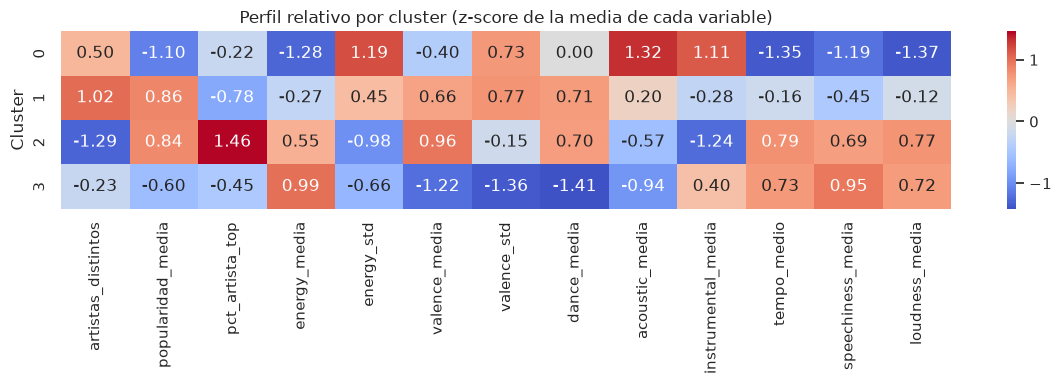

Accuracy del árbol descriptivo en test: 0.8369

Reglas del árbol de decisión:
|--- energy_media <= 0.73
|   |--- loudness_media <= -9.69
|   |   |--- valence_media <= 0.45
|   |   |   |--- acoustic_media <= 0.23
|   |   |   |   |--- class: 0
|   |   |   |--- acoustic_media >  0.23
|   |   |   |   |--- class: 0
|   |   |--- valence_media >  0.45
|   |   |   |--- acoustic_media <= 0.36
|   |   |   |   |--- class: 1
|   |   |   |--- acoustic_media >  0.36
|   |   |   |   |--- class: 0
|   |--- loudness_media >  -9.69
|   |   |--- energy_std <= 0.19
|   |   |   |--- artistas_distintos <= 272.50
|   |   |   |   |--- class: 2
|   |   |   |--- artistas_distintos >  272.50
|   |   |   |   |--- class: 1
|   |   |--- energy_std >  0.19
|   |   |   |--- valence_media <= 0.32
|   |   |   |   |--- class: 3
|   |   |   |--- valence_media >  0.32
|   |   |   |   |--- class: 1
|--- energy_media >  0.73
|   |--- valence_media <= 0.39
|   |   |--- dance_media <= 0.46
|   |   |   |--- pct_artista_top <= 

energy_media          0.2944
loudness_media        0.2769
valence_media         0.2741
energy_std            0.0591
artistas_distintos    0.0431
acoustic_media        0.0252
dance_media           0.0188
pct_artista_top       0.0084
popularidad_media     0.0000
valence_std           0.0000
dtype: float64


Distribución porcentual por cluster según país (top 6 + Otros):


country,BR,DE,GB,Otros,PL,RU,US
cluster,,,,,,,
0,3.7,6.1,9.9,45.7,6.4,7.8,20.4
1,6.1,7.9,9.3,41.3,6.9,6.9,21.6
2,12.2,9.1,7.0,34.3,11.5,10.2,15.7
3,5.4,10.3,5.7,43.1,8.0,13.4,14.0



Distribución porcentual por cluster según género:


gender,f,m,no informado
cluster,,,
0,23.3,65.5,11.2
1,27.5,63.6,8.9
2,30.8,62.0,7.2
3,14.8,78.4,6.8



Resumen de edad por cluster (excluyendo nulos):


,count,mean,median
cluster,,,
0,6815,28.2,25.0
1,16389,26.0,24.0
2,10007,22.6,21.0
3,8117,23.7,22.0



Top 5 artistas por cluster:


,cluster,rk,artist_name,total_escuchas
0,0,1,Boards of Canada,414417.0
1,0,2,Radiohead,261554.0
2,0,3,Bon Iver,219451.0
3,0,4,Sigur Rós,213049.0
4,0,5,The xx,182056.0
5,1,1,Arctic Monkeys,788233.0
6,1,2,Daft Punk,638227.0
7,1,3,The xx,609967.0
8,1,4,Radiohead,590150.0
9,1,5,Kings of Leon,514630.0


In [7]:
# 1) Perfil promedio y mediana por cluster en las variables originales
perfil_clusters = df_cluster.groupby("cluster")[features_clustering].agg(["mean", "median"])
medias_cluster = perfil_clusters.xs("mean", level=1, axis=1)
medianas_cluster = perfil_clusters.xs("median", level=1, axis=1)

print("Cantidad de usuarios por cluster:")
print(df_cluster["cluster"].value_counts().sort_index())
print("\nMedias por cluster:")
display(medias_cluster.round(3))

# Mapa de calor normalizado (z-score entre clusters) para visualizar el perfil relativo de cada grupo
medias_z = medias_cluster.apply(lambda s: (s - s.mean()) / (s.std() + 1e-9), axis=0)
plt.figure(figsize=(12, max(4, df_cluster["cluster"].nunique() * 0.9)))
sns.heatmap(medias_z, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Perfil relativo por cluster (z-score de la media de cada variable)")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

# 2) Árbol de decisión descriptivo usando las variables originales como predictores
X_tree = df_cluster[features_clustering]
y_tree = df_cluster["cluster"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X_tree, y_tree, test_size=0.25, random_state=RANDOM_STATE, stratify=y_tree
)

arbol = DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=RANDOM_STATE)
arbol.fit(X_tr, y_tr)
y_pred_tree = arbol.predict(X_te)

print(f"Accuracy del árbol descriptivo en test: {accuracy_score(y_te, y_pred_tree):.4f}")
print("\nReglas del árbol de decisión:")
print(export_text(arbol, feature_names=features_clustering))

importancias = pd.Series(arbol.feature_importances_, index=features_clustering).sort_values(ascending=False)
print("\nImportancia de variables en el árbol descriptivo:")
display(importancias.head(10).round(4))

# 3) Contexto demográfico (país, edad y género) desde users_clean
if "country" in df_cluster.columns:
    top_paises = df_cluster["country"].value_counts().head(6).index
    ct_pais = pd.crosstab(
        df_cluster["cluster"],
        df_cluster["country"].where(df_cluster["country"].isin(top_paises), other="Otros"),
        normalize="index",
    ) * 100
    print("\nDistribución porcentual por cluster según país (top 6 + Otros):")
    display(ct_pais.round(1))

if "gender" in df_cluster.columns:
    ct_genero = pd.crosstab(
        df_cluster["cluster"],
        df_cluster["gender"].fillna("no informado"),
        normalize="index",
    ) * 100
    print("\nDistribución porcentual por cluster según género:")
    display(ct_genero.round(1))

if "age" in df_cluster.columns:
    print("\nResumen de edad por cluster (excluyendo nulos):")
    display(df_cluster.groupby("cluster")["age"].agg(["count", "mean", "median"]).round(1))

# 4) Artistas más escuchados por cluster cruzando con vista_usuario_artista y artists
con.register("usuarios_cluster_tmp", df_cluster[["user_id", "cluster"]])
con.execute(f"CREATE OR REPLACE VIEW vista_usuario_artista AS SELECT * FROM {ruta_sql('vista_usuario_artista')}")

cols_vua = [row[1] for row in con.sql("DESCRIBE vista_usuario_artista").fetchall()]
col_escuchas_vua = "escuchas" if "escuchas" in cols_vua else next(
    (c for c in cols_vua if "escucha" in c.lower() or "reproduc" in c.lower() or "count" in c.lower()),
    "escuchas",
)

top_artistas_cluster = con.sql(f"""
    WITH escucha_cluster AS (
        SELECT
            u.cluster,
            vua.artist_id,
            SUM(vua.{col_escuchas_vua}) AS total_escuchas
        FROM vista_usuario_artista vua
        JOIN usuarios_cluster_tmp u USING (user_id)
        GROUP BY u.cluster, vua.artist_id
    ),
    rankeado AS (
        SELECT
            ec.cluster,
            a.artist_name,
            ec.total_escuchas,
            ROW_NUMBER() OVER (PARTITION BY ec.cluster ORDER BY ec.total_escuchas DESC) AS rk
        FROM escucha_cluster ec
        JOIN artists a USING (artist_id)
    )
    SELECT cluster, rk, artist_name, total_escuchas
    FROM rankeado
    WHERE rk <= 5
    ORDER BY cluster, rk
""").df()

print("\nTop 5 artistas por cluster:")
display(top_artistas_cluster)

### Hallazgos e interpretación de los clusters (Bloque 4)

A partir de los perfiles estadísticos, el mapa de calor relativo ($z$-score), el árbol de decisión descriptivo y el cruce con `users_clean`, `vista_usuario_artista` y `artists` sobre los **53.289 usuarios**, se identifican cuatro modos de escucha diferenciados:

1. **Caracterización de los cuatro clusters:**
   - **Cluster 0 (`9.606` usuarios — Perfil acústico, ambiental e introspectivo):** presenta los valores más bajos de `energy_media` (`0,532`), `loudness_media` (`-10,97 dB`) y `tempo_medio` (`118,99 BPM`), junto con los más altos de `acoustic_media` (`0,396`), `instrumental_media` (`0,344`) y `energy_std` (`0,252`). Se asocia a artistas como *Boards of Canada*, *Radiohead*, *Bon Iver*, *Sigur Rós* y *The xx*, y a una edad promedio superior a la del resto (`28,2` años).
   - **Cluster 1 (`21.280` usuarios — Perfil explorador y amplio):** es el segmento más numeroso, con mayor amplitud de repertorio (`artistas_distintos = 450,23`), menor dependencia de un único artista (`pct_artista_top = 0,077`) y valores equilibrados de valencia (`0,462`), bailabilidad (`0,528`) y energía (`0,661`), encabezado por *Arctic Monkeys*, *Daft Punk*, *The xx*, *Radiohead* y *Kings of Leon*.
   - **Cluster 2 (`12.438` usuarios — Perfil enérgico, positivo/bailable y concentrado):** combina alta energía (`0,766`), mayor `valence_media` (`0,486`), `dance_media` (`0,528`) y volumen (`-6,32 dB`) con la mayor concentración en su artista principal (`pct_artista_top = 0,180`) y menor cantidad de artistas distintos (`149,21`), con artistas como *Arctic Monkeys*, *System of a Down*, *Paramore*, *Rise Against* y *blink-182*, y la edad media más baja (`22,6` años).
   - **Cluster 3 (`9.965` usuarios — Perfil intenso y de baja valencia):** destaca por la mayor `energy_media` (`0,822`), alto volumen (`-6,43 dB`) y mayor `speechiness_media` (`0,089`), pero con los valores más bajos de `valence_media` (`0,312`) y `dance_media` (`0,398`), concentrando escuchas en bandas como *Katatonia*, *Amon Amarth*, *Opeth*, *Nightwish* y *Slayer*, con edad media de `23,7` años y predominio masculino (`78,4%`).

2. **Reglas del árbol de decisión descriptivo:**
   - El árbol de profundidad máxima `4` alcanza un **`accuracy` de `0,8369`** en el conjunto de prueba, mostrando que los segmentos son altamente recuperables a partir de reglas transparentes sobre las variables originales.
   - Los principales factores de separación son **`energy_media` (`0,2944`)**, **`loudness_media` (`0,2769`)** y **`valence_media` (`0,2741`)**, complementados en ramas secundarias por `energy_std` (`0,0591`) y `artistas_distintos` (`0,0431`).

3. **Contexto demográfico y sesgos del corpus:**
   - Las diferencias geográficas y demográficas (como el peso de `US`, `GB`, `DE`, `RU`, `PL` y `BR`, el sesgo de género hacia `m` en el dataset de Last.fm y la concentración etaria en torno a los 21–28 años) actúan como contexto descriptivo y reflejan los sesgos propios de la plataforma y del catálogo vinculado a Spotify[cite: 10].

## 5. Síntesis final y respuesta a las preguntas del modelado

A lo largo de este notebook se construyó, evaluó e interpretó un esquema de agrupamiento no supervisado sobre los **53.289 usuarios** activos del corpus (`vista_usuarios` enriquecida con `users_clean` y `artists`), respondiendo a las cuatro preguntas iniciales[cite: 8, 9]:

1. **¿Existen perfiles diferenciados según hábitos de reproducción y descriptores acústicos?**
   - **Sí.** Aunque los consumos musicales se distribuyen sobre un continuo sin fronteras rígidas, el análisis permite distinguir **cuatro perfiles de usuario bien diferenciados** en cuanto a intensidad sonora (`energy_media`, `loudness_media`), tono emocional y rítmico (`valence_media`, `dance_media`), carácter orgánico (`acoustic_media`, `instrumental_media`) y amplitud de repertorio (`artistas_distintos`, `pct_artista_top`):
     - **Cluster 0 (`9.606` usuarios — Acústico, ambiental e introspectivo):** baja energía (`0,532`), menor volumen (`-10,97 dB`) y tempo pausado (`118,99 BPM`), con alta presencia acústica (`0,396`) e instrumental (`0,344`), asociado a artistas como *Boards of Canada*, *Radiohead*, *Bon Iver*, *Sigur Rós* y *The xx*.
     - **Cluster 1 (`21.280` usuarios — Explorador y amplio):** segmento mayoritario (~40 % del total), con el mayor número de artistas distintos (`450,23`) y la menor concentración en un artista principal (`pct_artista_top = 0,077`), manteniendo valores equilibrados en energía (`0,661`), valencia (`0,462`) y bailabilidad (`0,528`), con referentes como *Arctic Monkeys*, *Daft Punk*, *The xx*, *Radiohead* y *Kings of Leon*.
     - **Cluster 2 (`12.438` usuarios — Enérgico, positivo/bailable y concentrado):** alta energía (`0,766`), mayor valencia (`0,486`), bailabilidad (`0,528`) y volumen (`-6,32 dB`), pero con fuerte concentración en pocos artistas (`pct_artista_top = 0,180` y `artistas_distintos = 149,21`), liderado por *Arctic Monkeys*, *System of a Down*, *Paramore*, *Rise Against* y *blink-182*.
     - **Cluster 3 (`9.965` usuarios — Intenso y de baja valencia):** máxima energía (`0,822`) y volumen (`-6,43 dB`) junto con los valores más bajos de valencia (`0,312`) y bailabilidad (`0,398`), concentrado en bandas de metal y rock pesado como *Katatonia*, *Amon Amarth*, *Opeth*, *Nightwish* y *Slayer*.

2. **¿Cómo se comparan las distintas familias de clustering y qué aporta la acumulación de evidencia?**
   - En los métodos **jerárquicos** (`linkage=average`, `k=4`) y de **densidad** (`DBSCAN` con `eps=1.8`, `min_samples=10`, `15,76 %` de ruido) se obtienen los mayores índices de **Silhouette** (`0,580` y `0,391`) al aislar grupos pequeños o zonas densas frente a observaciones periféricas, pero con bajo **Calinski-Harabasz** (`30,06` y `38,56